# 🛒 Negozio online – Analisi delle vendite e dei clienti

**Progetto di Francesco Autorino – Data Analyst**

🏪 Un negozio online inglese che vende articoli regalo, molti clienti sono grossisti.
📅 Da dicembre 2009 a dicembre 2011 · 1 milione di righe di vendita.

❓ **Le 6 domande**
1. Come vanno le vendite nel tempo?
2. Quali prodotti e quali paesi portano più soldi?
3. Chi sono i clienti migliori? (RFM)
4. Quanti clienti tornano a comprare? (coorti)
5. Quali prodotti vengono comprati insieme? (carrello)
6. Quanto pesano i resi?

🗂️ Dati: tabelle pulite in `02Dati/2Puliti` (script `01RaccoltaDati/02_pulizia.py`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick

PULITI = Path("../02Dati/2Puliti"); GRAFICI = Path("grafici"); GRAFICI.mkdir(exist_ok=True)
leggi = lambda n: pd.read_csv(PULITI / f"{n}.csv")
mens, go, prod, paesi = leggi("vendite_mensili"), leggi("vendite_giorno_ora"), leggi("prodotti"), leggi("paesi")
rfm, coorti, carr, resi_m, reg = leggi("clienti_rfm"), leggi("coorti"), leggi("carrello_coppie"), leggi("resi_mensili"), leggi("registro_pulizia")

# colori fissi: sempre gli stessi in tutti i grafici
UK, ESTERO, ACCENTO, GRIGIO = "#1f4e9c", "#eb6834", "#c8102e", "#9a9890"
SEG = {"Campioni": "#1f4e9c", "Fedeli": "#5da9e9", "Da non perdere": "#eb6834", "A rischio": "#eda100",
       "Nuovi clienti": "#1baf7a", "Da coltivare": "#8fd1b5", "Persi": "#9a9890"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left"})
sterline = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f} mln" if x >= 1e6 else f"£{x/1e3:,.0f}k")
def salva(n):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{n}.png", bbox_inches="tight", facecolor="white"); plt.show()
print(f"Ricavi totali: £{mens.ricavi.sum():,.0f} · Clienti registrati: {len(rfm):,} · Prodotti: {len(prod):,}")

Ricavi totali: £19,398,194 · Clienti registrati: 5,852 · Prodotti: 4,892


## 🧹 0. Cosa ho tolto durante la pulizia

In [2]:
reg[["passo", "righe_tolte", "righe_dopo"]]

,passo,righe_tolte,righe_dopo
0,1. Righe duplicate,34335,1033036
1,2. Rettifiche contabili (scontrini A),6,1033030
2,"3. Codici che non sono prodotti (spedizioni, c...",5817,1027213
3,4. Annullamenti e resi (spostati in resi.csv),17914,1009299
4,5. Quantità o prezzo ≤ 0,5961,1003338
5,6. Ordini enormi annullati subito (errori di i...,2,1003336


📝 Su 1.067.371 righe ne restano **1.003.336** di vendite vere.

⚠️ Il 13% dei ricavi viene da clienti **senza codice**: restano nei totali, ma non nelle analisi sui clienti (RFM e coorti).

## 📈 1. Come vanno le vendite nel tempo?

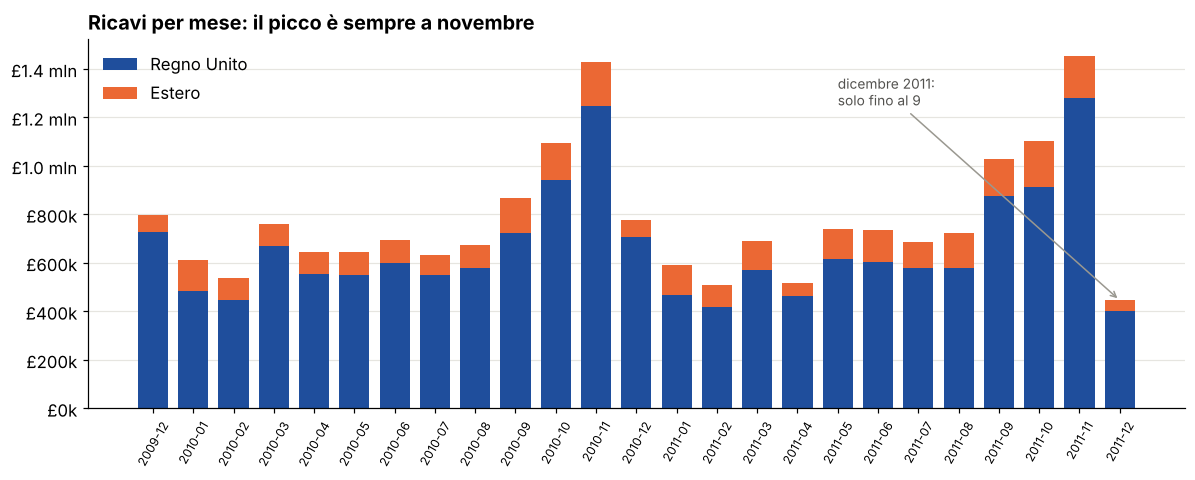

In [3]:
t = mens.pivot_table(index="mese", columns="area", values="ricavi").fillna(0)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(t.index, t["Regno Unito"], color=UK, label="Regno Unito", width=0.75)
ax.bar(t.index, t["Estero"], bottom=t["Regno Unito"], color=ESTERO, label="Estero", width=0.75)
ax.yaxis.set_major_formatter(sterline); ax.grid(axis="x", visible=False)
ax.set_title("Ricavi per mese: il picco è sempre a novembre")
ax.annotate("dicembre 2011:\nsolo fino al 9", xy=(len(t) - 1, t.iloc[-1].sum()), xytext=(17, 1.25e6),
            textcoords="data", fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="->", color=GRIGIO))
plt.xticks(rotation=60, fontsize=8); ax.legend(frameon=False, loc="upper left")
salva("01_ricavi_mensili")

In [4]:
m = mens.groupby("mese").ricavi.sum()
m.index = pd.PeriodIndex(m.index, freq="M")
gen_nov = lambda a: m[(m.index.year == a) & (m.index.month <= 11)].sum()
print(f"Gennaio-novembre 2010: £{gen_nov(2010):,.0f}")
print(f"Gennaio-novembre 2011: £{gen_nov(2011):,.0f}  ({(gen_nov(2011)/gen_nov(2010)-1)*100:+.1f}%)")
sn = m[(m.index.year == 2010) & (m.index.month.isin([9, 10, 11]))].sum() / m[m.index.year == 2010].sum()
print(f"Settembre-novembre 2010: {sn:.0%} dei ricavi dell'anno")

Gennaio-novembre 2010: £8,598,726
Gennaio-novembre 2011: £8,779,906  (+2.1%)
Settembre-novembre 2010: 36% dei ricavi dell'anno


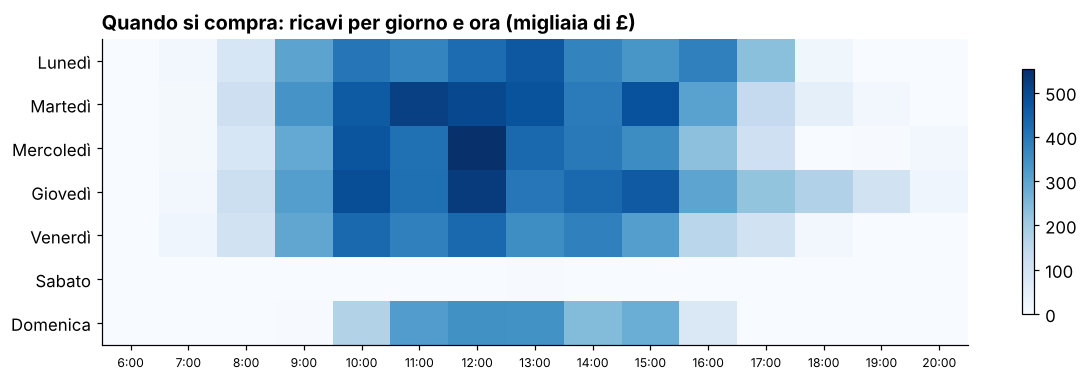

Sabato: £9,803 in tutto (un solo sabato con vendite, il 5/12/2009) → di sabato il negozio è chiuso


In [5]:
giorni = ["Lunedì", "Martedì", "Mercoledì", "Giovedì", "Venerdì", "Sabato", "Domenica"]
h = go.pivot_table(index="giorno_settimana", columns="ora", values="ricavi").reindex([g for g in giorni if g in set(go.giorno_settimana)])
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(h.fillna(0) / 1000, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(h.columns)), [f"{o}:00" for o in h.columns], fontsize=8)
ax.set_yticks(range(len(h.index)), h.index); ax.grid(False)
ax.set_title("Quando si compra: ricavi per giorno e ora (migliaia di £)")
plt.colorbar(im, ax=ax, shrink=0.8)
salva("02_giorno_ora")
print("Sabato: £{:,.0f} in tutto (un solo sabato con vendite, il 5/12/2009) → di sabato il negozio è chiuso".format(go[go.giorno_settimana == "Sabato"].ricavi.sum()))

📝 Le vendite sono **stagionali**: settembre-novembre fa oltre un terzo dell'anno, perché i grossisti si riforniscono per Natale.

📝 Il 2011 è quasi uguale al 2010: crescita piatta.

📝 Si compra soprattutto **a metà giornata (10-15), da lunedì a giovedì**; di sabato il negozio è chiuso: tipico di clienti aziendali, non privati.

## 🏆 2. Quali prodotti e quali paesi portano più soldi?

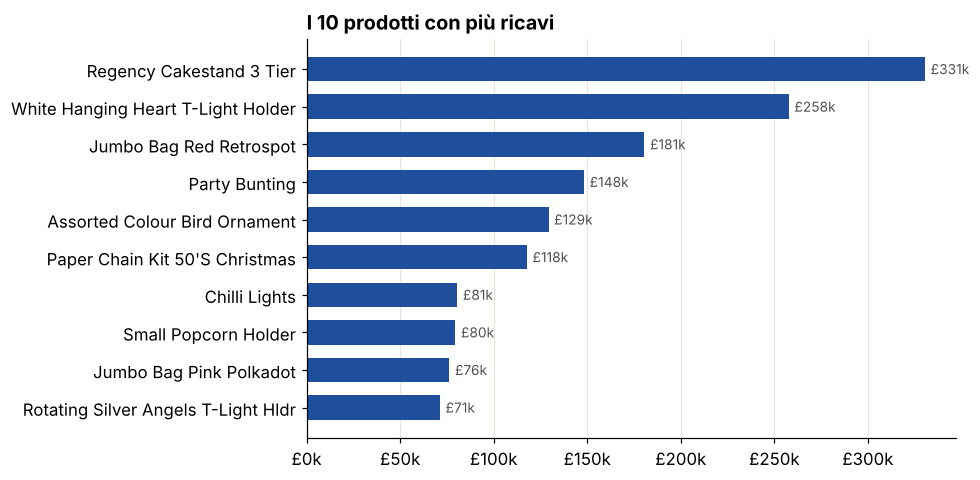

In [6]:
d = prod.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(d["descrizione"].str.title(), d["ricavi"], color=UK, height=0.65)
for y, v in enumerate(d["ricavi"]):
    ax.text(v + 3000, y, f"£{v/1000:,.0f}k", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(sterline); ax.grid(axis="y", visible=False)
ax.set_title("I 10 prodotti con più ricavi")
salva("03_top_prodotti")

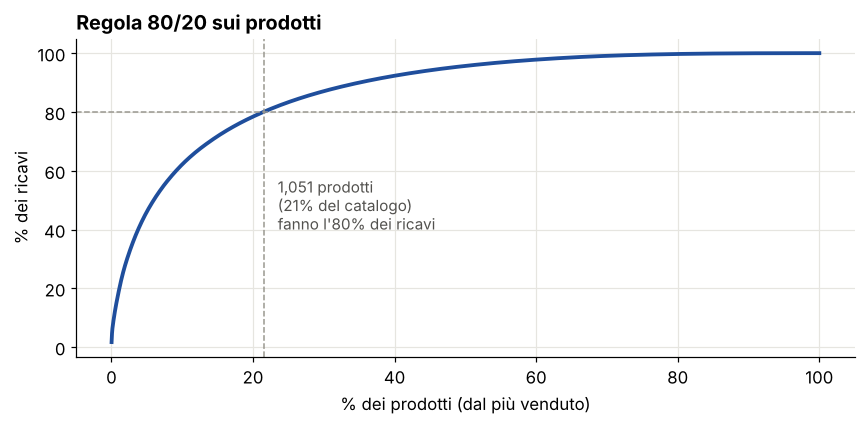

In [7]:
q = prod["ricavi"].sort_values(ascending=False).cumsum() / prod["ricavi"].sum()
n80 = (q < 0.8).sum() + 1
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(q) + 1) / len(q) * 100, q.values * 100, color=UK, lw=2.5)
ax.axhline(80, color=GRIGIO, ls="--", lw=1); ax.axvline(n80 / len(q) * 100, color=GRIGIO, ls="--", lw=1)
ax.text(n80 / len(q) * 100 + 2, 40, f"{n80:,} prodotti\n({n80/len(q):.0%} del catalogo)\nfanno l'80% dei ricavi", fontsize=10, color="#52514e")
ax.set_xlabel("% dei prodotti (dal più venduto)"); ax.set_ylabel("% dei ricavi")
ax.set_title("Regola 80/20 sui prodotti")
salva("04_pareto_prodotti")

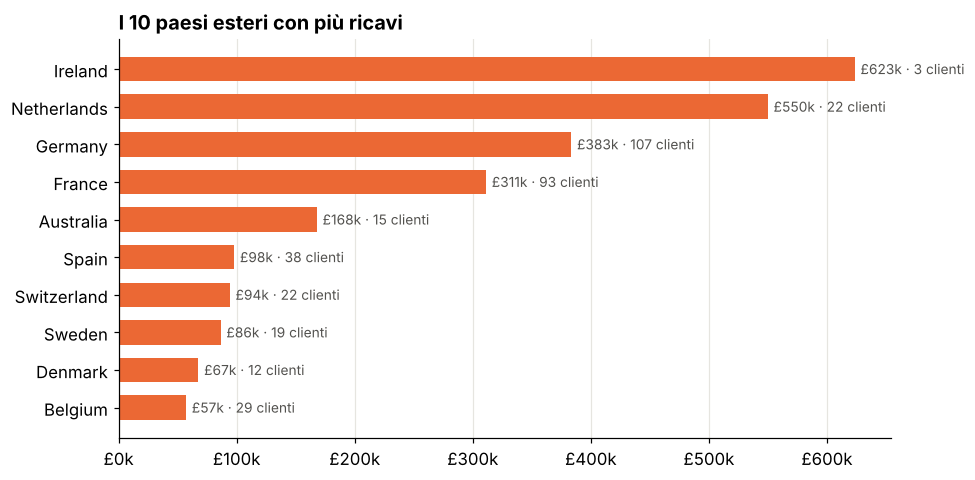

Regno Unito: 85% dei ricavi


In [8]:
e = paesi[paesi.paese != "United Kingdom"].head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(e["paese"], e["ricavi"], color=ESTERO, height=0.65)
for y, (v, c) in enumerate(zip(e["ricavi"], e["clienti"])):
    ax.text(v + 5000, y, f"£{v/1000:,.0f}k · {c} clienti", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(sterline); ax.grid(axis="y", visible=False)
ax.set_title("I 10 paesi esteri con più ricavi")
salva("05_paesi_esteri")
print(f"Regno Unito: {paesi.iloc[0].ricavi / paesi.ricavi.sum():.0%} dei ricavi")

📝 Il negozio vive del **Regno Unito** (85% dei ricavi).

📝 All'estero pochi clienti ma grandi: l'**Irlanda** fa 623.000 £ con soli 3 clienti, i **Paesi Bassi** hanno lo scontrino medio più alto (circa 2.500 £).

📝 Il catalogo è lunghissimo: circa **1 prodotto su 5 fa l'80% dei ricavi**.

## 👑 3. Chi sono i clienti migliori? (RFM)

**R** = da quanti giorni non compra · **F** = quante volte ha comprato · **M** = quanto ha speso. Ogni voce ha un punteggio da 1 a 5.

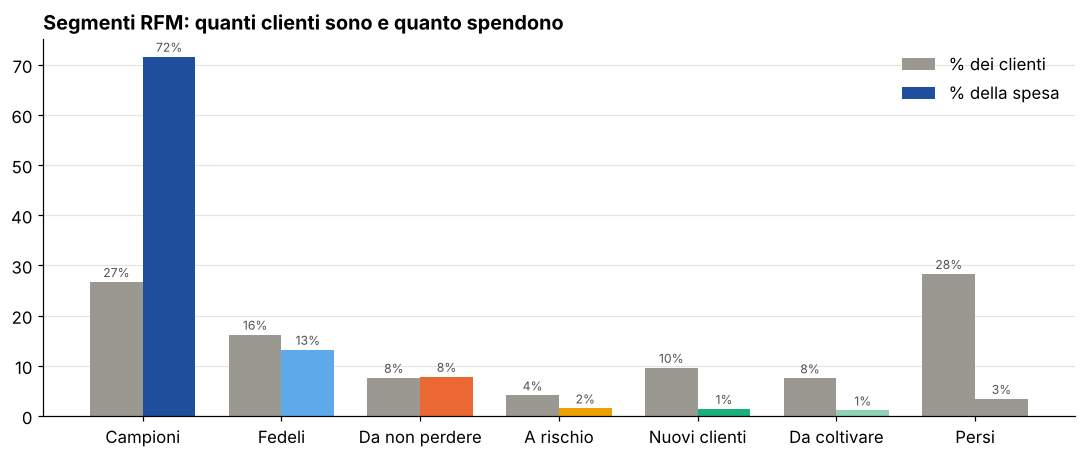

,clienti,spesa,giorni,% clienti,% spesa
segmento,,,,,
Campioni,1565,12053591.1,21.0,26.7,71.6
Fedeli,947,2218120.3,86.9,16.2,13.2
Da non perdere,444,1314731.7,352.3,7.6,7.8
A rischio,239,250057.0,386.0,4.1,1.5
Nuovi clienti,560,231565.4,28.1,9.6,1.4
Da coltivare,440,181147.5,109.5,7.5,1.1
Persi,1657,573701.7,451.0,28.3,3.4


In [9]:
s = (rfm.groupby("segmento").agg(clienti=("cliente_id", "size"), spesa=("spesa", "sum"),
                                 giorni=("recency_giorni", "mean")).reindex(SEG.keys()))
s["% clienti"] = (s.clienti / s.clienti.sum() * 100).round(1)
s["% spesa"] = (s.spesa / s.spesa.sum() * 100).round(1)
fig, ax = plt.subplots(figsize=(10, 4.3))
x = np.arange(len(s)); w = 0.38
ax.bar(x - w/2, s["% clienti"], w, color=GRIGIO, label="% dei clienti")
ax.bar(x + w/2, s["% spesa"], w, color=[SEG[k] for k in s.index], label="% della spesa")
for i, (a, b) in enumerate(zip(s["% clienti"], s["% spesa"])):
    ax.text(i - w/2, a + 1, f"{a:.0f}%", ha="center", fontsize=8, color="#52514e")
    ax.text(i + w/2, b + 1, f"{b:.0f}%", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, s.index); ax.grid(axis="x", visible=False); ax.legend(frameon=False)
ax.set_title("Segmenti RFM: quanti clienti sono e quanto spendono")
salva("06_segmenti_rfm")
s.round(1)

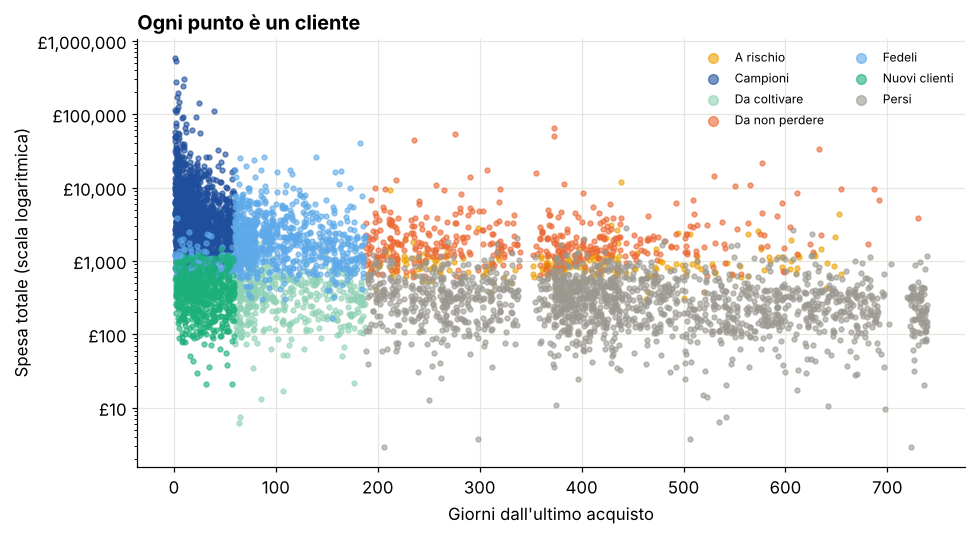

Il 10% dei clienti che spende di più fa il 63% della spesa


In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for seg, g in rfm.groupby("segmento"):
    ax.scatter(g["recency_giorni"], g["spesa"], s=10, alpha=0.6, color=SEG[seg], label=seg)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax.set_xlabel("Giorni dall'ultimo acquisto"); ax.set_ylabel("Spesa totale (scala logaritmica)")
ax.set_title("Ogni punto è un cliente")
ax.legend(frameon=False, fontsize=8, markerscale=2, ncol=2)
salva("07_rfm_clienti")
top10 = rfm.spesa.nlargest(int(len(rfm) * 0.1)).sum() / rfm.spesa.sum()
print(f"Il 10% dei clienti che spende di più fa il {top10:.0%} della spesa")

📝 I **Campioni** sono il 27% dei clienti ma fanno il **72% della spesa**.

📝 Il 10% dei clienti migliori vale da solo quasi i **due terzi** dei ricavi: perderne anche pochi è un rischio.

📝 Il segmento da attaccare subito sono i **"Da non perdere"**: 444 clienti che spendevano molto (1,3 milioni £ in tutto) ma non comprano da quasi un anno.

## 🔁 4. Quanti clienti tornano a comprare? (coorti)

Una **coorte** è il gruppo di clienti che ha fatto il primo acquisto nello stesso mese.

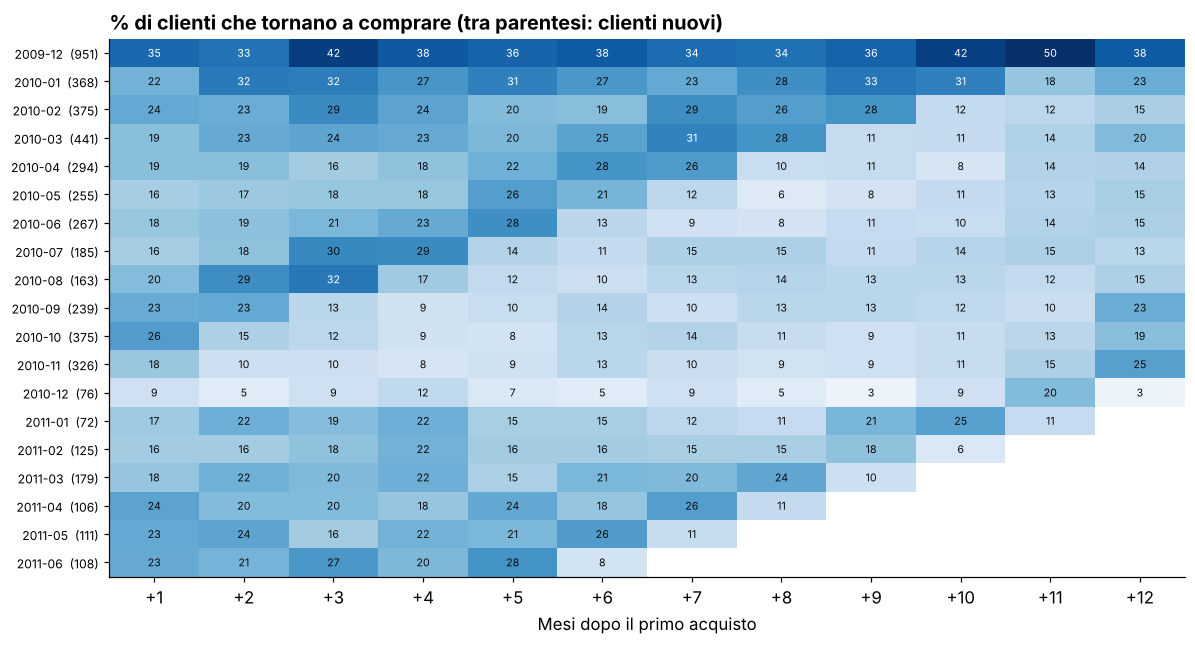

In [11]:
mat = coorti[coorti.mesi_dopo <= 12].pivot_table(index="coorte", columns="mesi_dopo", values="ritorno_pct")
dim = coorti[coorti.mesi_dopo == 0].set_index("coorte")["clienti_iniziali"]
mat = mat.loc[[c for c in mat.index if c <= "2011-06"]]
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(mat.iloc[:, 1:], cmap="Blues", vmin=0, vmax=45, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(1, mat.shape[1]):
        v = mat.iloc[i, j]
        if pd.notna(v): ax.text(j - 1, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 30 else "#0b0b0b")
ax.set_xticks(range(mat.shape[1] - 1), [f"+{m}" for m in mat.columns[1:]])
ax.set_yticks(range(mat.shape[0]), [f"{c}  ({dim[c]})" for c in mat.index], fontsize=8); ax.grid(False)
ax.set_xlabel("Mesi dopo il primo acquisto"); ax.set_title("% di clienti che tornano a comprare (tra parentesi: clienti nuovi)")
salva("08_coorti")

In [12]:
media = coorti[(coorti.coorte != "2009-12") & coorti.mesi_dopo.isin([1, 3, 6, 12])].groupby("mesi_dopo").ritorno_pct.mean()
print("Ritorno medio (coorti 2010-2011, senza dicembre 2009):"); print(media.round(1).to_string())
print(f"Clienti con un solo acquisto: {(rfm.frequenza == 1).mean():.0%} (fanno il {rfm[rfm.frequenza == 1].spesa.sum() / rfm.spesa.sum():.1%} della spesa)")

Ritorno medio (coorti 2010-2011, senza dicembre 2009):
mesi_dopo
1     20.4
3     20.7
6     16.8
12    16.7
Clienti con un solo acquisto: 28% (fanno il 3.3% della spesa)


📝 Solo **1 cliente nuovo su 5 torna il mese dopo**, e la percentuale resta intorno al 15-20% nei mesi seguenti.

📝 La coorte di **dicembre 2009** sembra fortissima perché contiene anche i vecchi clienti già attivi prima dell'inizio dei dati: per questo la escludo dalle medie.

📝 Il 28% dei clienti compra **una volta sola** e poi sparisce: c'è spazio per email di benvenuto e offerte sul secondo ordine.

## 🛒 5. Quali prodotti vengono comprati insieme?

**Lift** = quante volte la coppia appare insieme più del caso. Lift 5 = cinque volte più del normale.

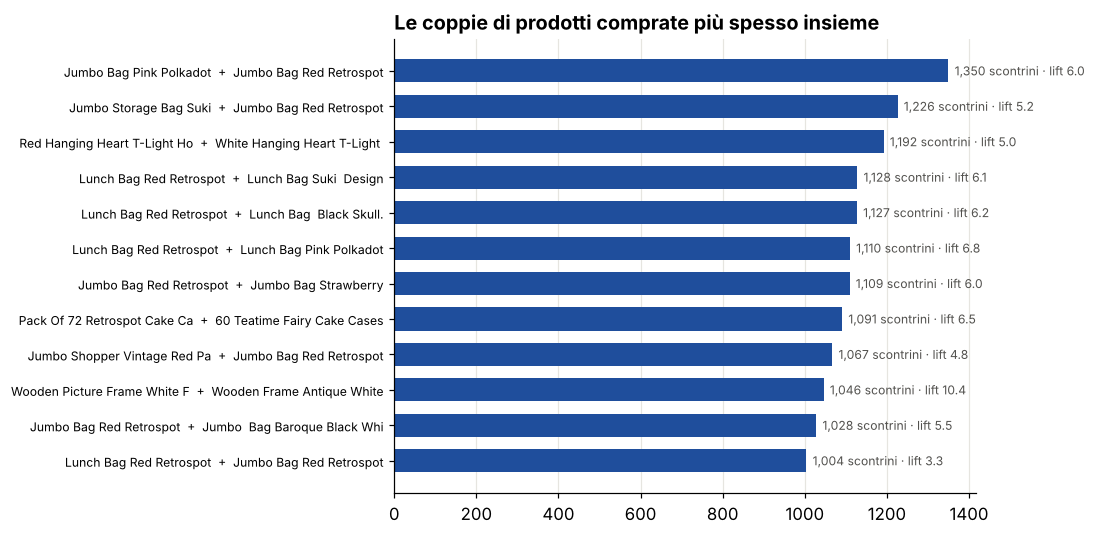

,prodotto_a,prodotto_b,ordini_insieme,lift
161,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,514,38.9
181,SET/10 PINK POLKADOT PARTY CANDLES,SET/10 BLUE SPOTTY PARTY CANDLES,485,37.8
173,PINK POLKADOT CUP,BLUE POLKADOT CUP,497,34.0
187,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,483,29.9
104,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,600,28.6


In [13]:
d = carr.head(12).iloc[::-1]
nomi = (d["prodotto_a"].str.title().str.slice(0, 28) + "  +  " + d["prodotto_b"].str.title().str.slice(0, 28))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(nomi, d["ordini_insieme"], color=UK, height=0.65)
for y, (v, l) in enumerate(zip(d["ordini_insieme"], d["lift"])):
    ax.text(v + 15, y, f"{v:,} scontrini · lift {l}", va="center", fontsize=8, color="#52514e")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Le coppie di prodotti comprate più spesso insieme")
salva("09_carrello")
carr.sort_values("lift", ascending=False).head(5)[["prodotto_a", "prodotto_b", "ordini_insieme", "lift"]]

📝 Le coppie più forti sono **varianti dello stesso prodotto** (borse jumbo di colori diversi, portacandele rosso e bianco, lunch bag): chi ne compra uno spesso prende tutta la serie.

💡 Idea pratica: mostrare "**completa la collezione**" sulla pagina del prodotto, o vendere set già pronti.

## ↩️ 6. Quanto pesano i resi?

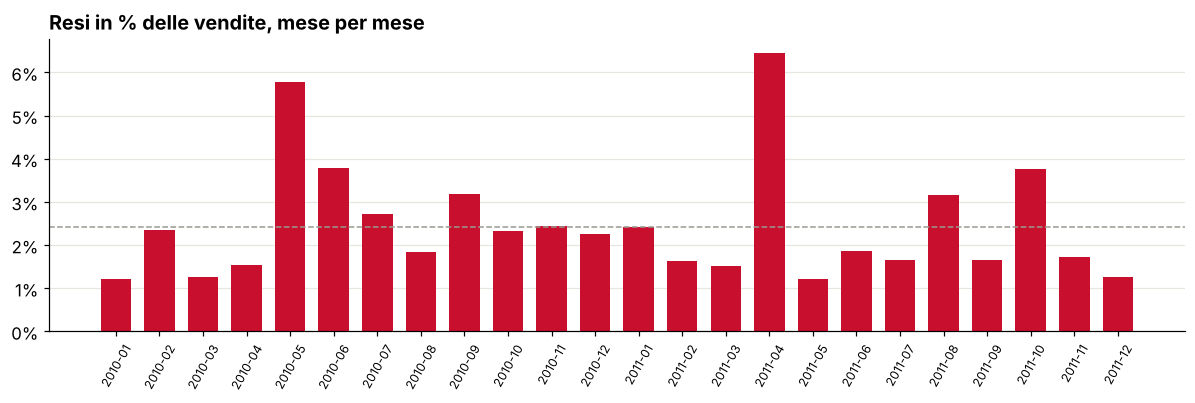

Resi totali: £470,773 = 2.4% delle vendite


In [14]:
r = resi_m[resi_m.mese != "2009-12"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(r["mese"], r["resi_su_vendite_pct"], color=ACCENTO, width=0.7)
ax.axhline(r["valore_resi"].sum() / r["ricavi"].sum() * 100, color=GRIGIO, ls="--", lw=1)
ax.set_title("Resi in % delle vendite, mese per mese"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.xticks(rotation=60, fontsize=8); ax.grid(axis="x", visible=False)
salva("10_resi_mensili")
print(f"Resi totali: £{resi_m.valore_resi.sum():,.0f} = {resi_m.valore_resi.sum() / resi_m.ricavi.sum():.1%} delle vendite")

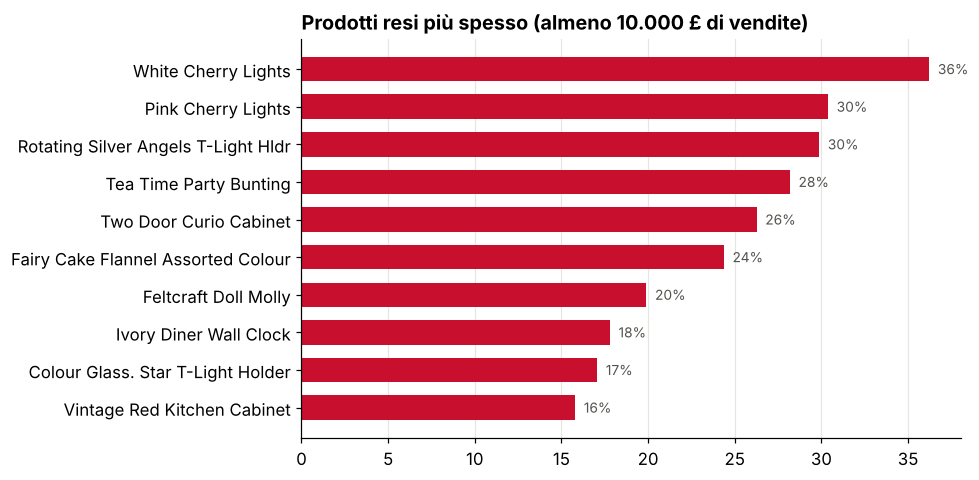

In [15]:
p = prod[prod.ricavi >= 10000].nlargest(10, "tasso_reso_pct").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(p["descrizione"].str.title(), p["tasso_reso_pct"], color=ACCENTO, height=0.65)
for y, v in enumerate(p["tasso_reso_pct"]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
ax.grid(axis="y", visible=False); ax.set_title("Prodotti resi più spesso (almeno 10.000 £ di vendite)")
salva("11_prodotti_resi")

📝 I resi valgono circa il **2,4% delle vendite**: un livello basso e stabile.

📝 Ma alcuni prodotti hanno un problema: le **luci a ciliegia** e il **portacandele con angeli rotanti** tornano indietro in un caso su tre. Da controllare qualità o descrizione.

## ✅ Conclusioni

1. 📈 **Vendite**: 19,4 milioni £ in due anni, crescita piatta nel 2011, forte stagionalità di Natale (settembre-novembre = oltre un terzo dell'anno).
2. 🏆 **Prodotti e paesi**: l'85% dei ricavi dal Regno Unito; il 21% dei prodotti fa l'80% dei ricavi.
3. 👑 **Clienti**: i Campioni (27% dei clienti) fanno il 72% della spesa. 444 clienti importanti sono "Da non perdere".
4. 🔁 **Ritorno**: circa 1 nuovo cliente su 5 torna il mese dopo; il 28% compra una volta sola.
5. 🛒 **Carrello**: si comprano insieme le varianti dello stesso prodotto → set e "completa la collezione".
6. ↩️ **Resi**: 2,4% delle vendite, concentrati su pochi prodotti.

⚠️ **Limiti**: dati fino al 9 dicembre 2011 · 13% dei ricavi senza codice cliente · niente costi, quindi niente margini.